# Advanced Data Preparation with Python (Car Data)

This notebook demonstrates advanced data preparation techniques with pandas using scraped car data from AutoScout24. It is an exercise: complete the empty code cells by applying the steps from the apartment data solution notebook (advanced_data_preparation_apartment_data_solution.ipynb). 
We will cover the following operations:

- Extracting information from raw data using regular expressions
- Counting and removing missing and duplicated values
- Creating new variables using string manipulation
- Discretization and One Hot Encoding
- Scaling and standardization
- Transformations (log, square root, Box-Cox)
- Combining data using .merge()
- Sorting, reshaping and pivoting data

## Libraries and settings

In [341]:
# Libraries
import os
import re
import time
import fnmatch
import numpy as np
import pandas as pd
import seaborn as sns
from datetime import datetime
import matplotlib.pyplot as plt

# Ignore warnings
import warnings
warnings.filterwarnings("ignore")

# Get current working directory
print(os.getcwd())

/workspaces/python_data_preparation


## Importing data

In [342]:
# Import data from csv to pandas dataframe named 'df'
df = pd.read_csv('./Data/autoscout24_data.csv', sep=";", encoding='utf-8')

# Change the column names to lowercase
df.columns = df.columns.str.lower()

# Display the first 5 rows of the dataframe
df.head()


,url_short,offer_id,scrape_dt,type,price_raw,hp_raw,init_regist,mileage_raw,fuel_type,transmission,dealer_name,dealer_plz,dealer_city,dealer_street_house_nr,dealer_telnr,init_regist_my,init_regist_month,init_regist_year,init_regist_dt
0,https://www.autoscout24.ch/7324420,7324420,2020_03_17 07:34:45,AUDI A5 Sportback 3.0 TDI quattro S-tronic (Li...,CHF 22'500.–,245 PS,10.2014,75'000 km,Diesel,Automatisiertes Schaltgetriebe,***confidential***,8488,Turbenthal,Mettlenstrasse 3,***confidential***,10.2014,10.0,2014.0,2014-10
1,https://www.autoscout24.ch/7512768,7512768,2020_03_17 07:34:55,MERCEDES-BENZ SLK 200 7G-Tronic (Cabriolet),CHF 23'749.–,184 PS,6.2013,46'655 km,Benzin,Automat sequentiell,***confidential***,3186,Düdingen,Brugerastrasse 60,***confidential***,6.2013,6.0,2013.0,2013-06
2,https://www.autoscout24.ch/7512034,7512034,2020_03_17 07:35:03,MERCEDES-BENZ C 350 Avantgarde 4Matic 7G-Troni...,CHF 18'500.–,306 PS,6.2011,138'955 km,Benzin,Automat sequentiell,***confidential***,1262,Eysins,1262 Eysins,***confidential***,6.2011,6.0,2011.0,2011-06
3,https://www.autoscout24.ch/7512728,7512728,2020_03_17 07:35:06,MERCEDES-BENZ A 45 AMG 4Matic Speedshift 7G-DC...,CHF 36'000.–,360 PS,8.2015,43'000 km,Benzin,Automatisiertes Schaltgetriebe,***confidential***,4314,Zeiningen,Am Stutz 21,***confidential***,8.2015,8.0,2015.0,2015-08
4,https://www.autoscout24.ch/7490242,7490242,2020_03_17 07:35:16,AUDI A5 Sportback 2.0 TFSI Sport quattro S-tro...,CHF 48'500.–,252 PS,9.2018,43'300 km,Benzin,Automatisiertes Schaltgetriebe,***confidential***,3250,Lyss,3250 Lyss,***confidential***,9.2018,9.0,2018.0,2018-09


## Count number of rows and columns in the data frame

In [343]:
# Count number of rows and columns in the data frame
print(f"Number of rows: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")

Number of rows: 3980
Number of columns: 19


## Get data types (raw-format from web scraper)

In [344]:
# Get data types of each column
print(df.dtypes)

url_short                     str
offer_id                    int64
scrape_dt                     str
type                          str
price_raw                     str
hp_raw                        str
init_regist                   str
mileage_raw                   str
fuel_type                     str
transmission                  str
dealer_name                   str
dealer_plz                  int64
dealer_city                   str
dealer_street_house_nr        str
dealer_telnr                  str
init_regist_my                str
init_regist_month         float64
init_regist_year          float64
init_regist_dt                str
dtype: object


## Extract information from raw data using regular expressions (regex)

### Extract numerical values from mileage_raw

In [345]:
# Extract numerical values (note the 'join' function)
mileage_raw_rows = []

for i in df['mileage_raw']:
    digits = re.findall(r"\d+", i)
    try:
        d2 = "".join(digits)
    except IndexError:
        d2 = None
    mileage_raw_rows.append(d2)

# Save as new variable in the pandas data frame
df['mileage'] = pd.Series(mileage_raw_rows, dtype="int64")

# Show first records of data frame
df[['mileage_raw', 'mileage']].head()


,mileage_raw,mileage
0,75'000 km,75000
1,46'655 km,46655
2,138'955 km,138955
3,43'000 km,43000
4,43'300 km,43300


### Extract numerical values from hp_raw

In [346]:
# Extract numerical values (note the 'join' function)
hp_raw_rows = []

for i in df['hp_raw']:
    digits = re.findall(r"\d+", i)
    try:
        d2 = "".join(digits)
    except IndexError:
        d2 = None
    hp_raw_rows.append(d2)

# Save as new variable in the pandas data frame
df['hp'] = pd.Series(hp_raw_rows, dtype="int64")

# Show first records of data frame
df[['hp_raw', 'hp']].head()


,hp_raw,hp
0,245 PS,245
1,184 PS,184
2,306 PS,306
3,360 PS,360
4,252 PS,252


### Extract numerical values from price_raw

In [347]:
# Extract numerical values (note the 'join' function)
price_raw_rows = []

for i in df['price_raw']:
    digits = re.findall(r"\d+", i)
    try:
        d2 = "".join(digits)
    except IndexError:
        d2 = None
    price_raw_rows.append(d2)

# Save as new variable in the pandas data frame
df['price'] = pd.Series(price_raw_rows, dtype="int64")

# Show first records of data frame
df[['price_raw', 'price']].head()


,price_raw,price
0,CHF 22'500.–,22500
1,CHF 23'749.–,23749
2,CHF 18'500.–,18500
3,CHF 36'000.–,36000
4,CHF 48'500.–,48500


### Get data types of all variables, including the new ones

In [348]:
# Get data types of all variables
df.dtypes

url_short                     str
offer_id                    int64
scrape_dt                     str
type                          str
price_raw                     str
hp_raw                        str
init_regist                   str
mileage_raw                   str
fuel_type                     str
transmission                  str
dealer_name                   str
dealer_plz                  int64
dealer_city                   str
dealer_street_house_nr        str
dealer_telnr                  str
init_regist_my                str
init_regist_month         float64
init_regist_year          float64
init_regist_dt                str
mileage                     int64
hp                          int64
price                       int64
dtype: object

## Count and remove missing values

In [349]:
# Count and remove missing values
print("Missing values before removing: ", df.isnull().sum().sum())
df = df.dropna()
print("Missing values after removing: ", df.isnull().sum().sum())

# Reset the index of the dataframe
df = df.reset_index(drop=True)

Missing values before removing:  23
Missing values after removing:  0


## Count and remove duplicated values

In [350]:
# Count and remove duplicates
print("Number of duplicates before removing: ", df.duplicated().sum())
df = df.drop_duplicates()
print("Number of duplicates after removing: ", df.duplicated().sum())

# Reset the index of the dataframe
df = df.reset_index(drop=True)

Number of duplicates before removing:  0
Number of duplicates after removing:  0


## Use string manipulation methods to create additional variables from the car type

### Change strings in 'type' to uppercase

In [351]:
df.head(1)

,url_short,offer_id,scrape_dt,type,price_raw,hp_raw,init_regist,mileage_raw,fuel_type,transmission,...,dealer_city,dealer_street_house_nr,dealer_telnr,init_regist_my,init_regist_month,init_regist_year,init_regist_dt,mileage,hp,price
0,https://www.autoscout24.ch/7324420,7324420,2020_03_17 07:34:45,AUDI A5 Sportback 3.0 TDI quattro S-tronic (Li...,CHF 22'500.–,245 PS,10.2014,75'000 km,Diesel,Automatisiertes Schaltgetriebe,...,Turbenthal,Mettlenstrasse 3,***confidential***,10.2014,10.0,2014.0,2014-10,75000,245,22500


In [352]:
# Change strings in 'type' to uppercase and remove leading/trailing spaces
df['type'] = df['type'].str.upper()
df['type'] = df['type'].str.strip()

# Display variable 'type'
df['type'].head()


0    AUDI A5 SPORTBACK 3.0 TDI QUATTRO S-TRONIC (LI...
1          MERCEDES-BENZ SLK 200 7G-TRONIC (CABRIOLET)
2    MERCEDES-BENZ C 350 AVANTGARDE 4MATIC 7G-TRONI...
3    MERCEDES-BENZ A 45 AMG 4MATIC SPEEDSHIFT 7G-DC...
4    AUDI A5 SPORTBACK 2.0 TFSI SPORT QUATTRO S-TRO...
Name: type, dtype: str

### Calculate length of strings in 'type'

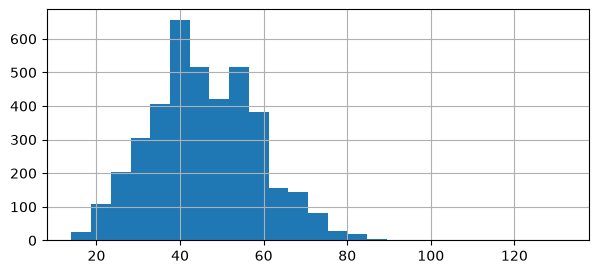

In [353]:
# New variable 'type_len' with the length of strings in 'type' (use .apply())
df['type_len'] = df['type'].str.len()

# Display variables 'type' and 'type_len'
df[['type_len', 'type']].head()

# Plot histogram of variable 'type_len'
ax = df['type_len'].hist(bins=25,figsize=(7, 3))

### Create binary (0/1) variable 'luxury_car'

In [354]:
df['type'].head(50)

0     AUDI A5 SPORTBACK 3.0 TDI QUATTRO S-TRONIC (LI...
1           MERCEDES-BENZ SLK 200 7G-TRONIC (CABRIOLET)
2     MERCEDES-BENZ C 350 AVANTGARDE 4MATIC 7G-TRONI...
3     MERCEDES-BENZ A 45 AMG 4MATIC SPEEDSHIFT 7G-DC...
4     AUDI A5 SPORTBACK 2.0 TFSI SPORT QUATTRO S-TRO...
5          MERCEDES-BENZ SLK 200 KOMPRESSOR (CABRIOLET)
6     MERCEDES-BENZ C 350 ELÉGANCE SPORT EDITION 4MA...
7          SEAT IBIZA SC 1.4 TSI CUPRA DSG (KLEINWAGEN)
8              PORSCHE 911 TURBO CABRIO PDK (CABRIOLET)
9               VW GOLF 1.4 TSI COMFORTLINE (LIMOUSINE)
10        AUDI RS3 2.5 TSI QUATTRO S-TRONIC (LIMOUSINE)
11                VW GOLF 2.0 TSI R 4MOTION (LIMOUSINE)
12    MERCEDES-BENZ A 250 SPORT 4MATIC 7G-DCT (LIMOU...
13                              BMW 1ER M COUPÉ (COUPÉ)
14        AUDI RS3 2.5 TSI QUATTRO S-TRONIC (LIMOUSINE)
15                     BMW M4 CABRIOLET DKG (CABRIOLET)
16    MERCEDES-BENZ GLE 250 D 4MATIC 9G-TRONIC (SUV ...
17    AUDI A7 SPORTBACK 3.0 TFSI QUATTRO S-TRONI

In [355]:
# Create a pattern which can be used to search the variable 'type'
pattern = 'LUXURY|SUV'

# Create new variable 'luxury_car' as binary dummy (0/1) variable
df['luxury_car'] = df['type'].str.contains(pat=pattern).astype(int)

# Count the number of luxury cars
print(df['luxury_car'].sum())

# Show values
df.loc[
    df['luxury_car'] == 1,
    ['price', 'luxury_car']
].head(20)

905


,price,luxury_car
16,31500,1
18,19900,1
23,29999,1
24,28750,1
27,19500,1
36,47900,1
39,33800,1
40,23800,1
47,24900,1
62,78000,1


### Create variable 'price_per_hp'

In [356]:
# Create variable 'price_per_hp' (round to 2 decimal places)
df['price_per_hp'] = (df['price']/df['hp']).round(2) 

# Display variables 'price', 'hp' and 'price_per_hp'
df[['price', 'hp', 'price_per_hp']].head()

,price,hp,price_per_hp
0,22500,245,91.84
1,23749,184,129.07
2,18500,306,60.46
3,36000,360,100.00
4,48500,252,192.46


### Include current datetime as time stamp

In [357]:
# Include current datetime as time stamp in the format 'YYYY-MM-DD HH:MM:SS'
df['datetime'] = datetime.now().strftime("%Y-%m-%d %H:%M:%S")

df.head()

,url_short,offer_id,scrape_dt,type,price_raw,hp_raw,init_regist,mileage_raw,fuel_type,transmission,...,init_regist_month,init_regist_year,init_regist_dt,mileage,hp,price,type_len,luxury_car,price_per_hp,datetime
0,https://www.autoscout24.ch/7324420,7324420,2020_03_17 07:34:45,AUDI A5 SPORTBACK 3.0 TDI QUATTRO S-TRONIC (LI...,CHF 22'500.–,245 PS,10.2014,75'000 km,Diesel,Automatisiertes Schaltgetriebe,...,10.0,2014.0,2014-10,75000,245,22500,54,0,91.84,2026-10-18 09:52:06
1,https://www.autoscout24.ch/7512768,7512768,2020_03_17 07:34:55,MERCEDES-BENZ SLK 200 7G-TRONIC (CABRIOLET),CHF 23'749.–,184 PS,6.2013,46'655 km,Benzin,Automat sequentiell,...,6.0,2013.0,2013-06,46655,184,23749,43,0,129.07,2026-10-18 09:52:06
2,https://www.autoscout24.ch/7512034,7512034,2020_03_17 07:35:03,MERCEDES-BENZ C 350 AVANTGARDE 4MATIC 7G-TRONI...,CHF 18'500.–,306 PS,6.2011,138'955 km,Benzin,Automat sequentiell,...,6.0,2011.0,2011-06,138955,306,18500,59,0,60.46,2026-10-18 09:52:06
3,https://www.autoscout24.ch/7512728,7512728,2020_03_17 07:35:06,MERCEDES-BENZ A 45 AMG 4MATIC SPEEDSHIFT 7G-DC...,CHF 36'000.–,360 PS,8.2015,43'000 km,Benzin,Automatisiertes Schaltgetriebe,...,8.0,2015.0,2015-08,43000,360,36000,59,0,100.00,2026-10-18 09:52:06
4,https://www.autoscout24.ch/7490242,7490242,2020_03_17 07:35:16,AUDI A5 SPORTBACK 2.0 TFSI SPORT QUATTRO S-TRO...,CHF 48'500.–,252 PS,9.2018,43'300 km,Benzin,Automatisiertes Schaltgetriebe,...,9.0,2018.0,2018-09,43300,252,48500,61,0,192.46,2026-10-18 09:52:06


## Discretization of numerical data

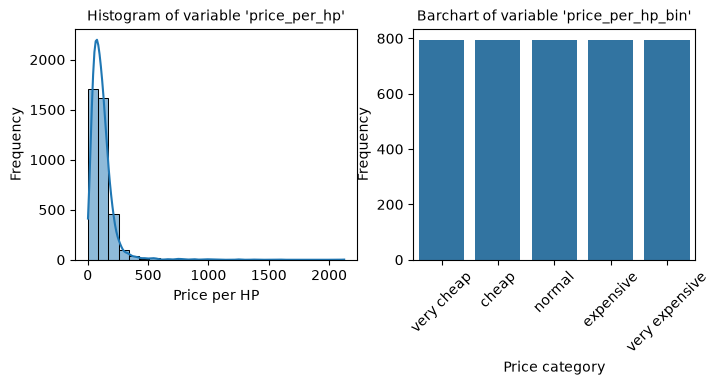

['normal', 'expensive', 'cheap', 'very expensive', 'very cheap']
Categories (5, str): ['very cheap' < 'cheap' < 'normal' < 'expensive' < 'very expensive']

In [358]:
# Discretization of the variable 'price_per_hp' into 5 bins
# (note the 'qcut' function)
df['price_per_hp_bin'] = pd.qcut(df['price_per_hp'],
                                q=5,
                                labels=['very cheap',
                                        'cheap',
                                        'normal',
                                        'expensive',
                                        'very expensive'])

# Show histogram of price_per_hp and barchart of variable 'price_per_hp_bin'
plt.figure(figsize=(8, 3))

# Create a 1x2 grid
plt.subplot(1, 2, 1)
sns.histplot(df['price_per_hp'], bins=25, kde=True)
plt.title("Histogram of variable 'price_per_hp'", fontsize=10)
plt.xlabel('Price per HP')
plt.ylabel('Frequency')

plt.subplot(1, 2, 2)
sns.countplot(data=df, x='price_per_hp_bin', orient='v')
plt.title("Barchart of variable 'price_per_hp_bin'", fontsize=10)
plt.xlabel('Price category')
plt.ylabel('Frequency')
plt.xticks(rotation=45)
plt.show()

# Display variables 'price_per_hp' and 'price_per_hp_bin'
df[['price_per_hp', 'price_per_hp_bin']].head()

# Show unique values
df['price_per_hp_bin'].unique()


## One Hot Encoding

In [359]:
df.head()

,url_short,offer_id,scrape_dt,type,price_raw,hp_raw,init_regist,mileage_raw,fuel_type,transmission,...,init_regist_year,init_regist_dt,mileage,hp,price,type_len,luxury_car,price_per_hp,datetime,price_per_hp_bin
0,https://www.autoscout24.ch/7324420,7324420,2020_03_17 07:34:45,AUDI A5 SPORTBACK 3.0 TDI QUATTRO S-TRONIC (LI...,CHF 22'500.–,245 PS,10.2014,75'000 km,Diesel,Automatisiertes Schaltgetriebe,...,2014.0,2014-10,75000,245,22500,54,0,91.84,2026-10-18 09:52:06,normal
1,https://www.autoscout24.ch/7512768,7512768,2020_03_17 07:34:55,MERCEDES-BENZ SLK 200 7G-TRONIC (CABRIOLET),CHF 23'749.–,184 PS,6.2013,46'655 km,Benzin,Automat sequentiell,...,2013.0,2013-06,46655,184,23749,43,0,129.07,2026-10-18 09:52:06,expensive
2,https://www.autoscout24.ch/7512034,7512034,2020_03_17 07:35:03,MERCEDES-BENZ C 350 AVANTGARDE 4MATIC 7G-TRONI...,CHF 18'500.–,306 PS,6.2011,138'955 km,Benzin,Automat sequentiell,...,2011.0,2011-06,138955,306,18500,59,0,60.46,2026-10-18 09:52:06,cheap
3,https://www.autoscout24.ch/7512728,7512728,2020_03_17 07:35:06,MERCEDES-BENZ A 45 AMG 4MATIC SPEEDSHIFT 7G-DC...,CHF 36'000.–,360 PS,8.2015,43'000 km,Benzin,Automatisiertes Schaltgetriebe,...,2015.0,2015-08,43000,360,36000,59,0,100.00,2026-10-18 09:52:06,normal
4,https://www.autoscout24.ch/7490242,7490242,2020_03_17 07:35:16,AUDI A5 SPORTBACK 2.0 TFSI SPORT QUATTRO S-TRO...,CHF 48'500.–,252 PS,9.2018,43'300 km,Benzin,Automatisiertes Schaltgetriebe,...,2018.0,2018-09,43300,252,48500,61,0,192.46,2026-10-18 09:52:06,very expensive


In [360]:
# One Hot Encoding of the variable 'price_per_hp_bin'
try:
    df = pd.get_dummies(df,
                        columns=['price_per_hp_bin'],
                        drop_first=False)
except KeyError:
    print("Dummy variables already exist")

# Convert boolean values to integers (0 and 1)
dummy_cols = df.filter(like='price_per_hp_bin').columns
df[dummy_cols] = df[dummy_cols].astype(int)

# Show values of the new dummy variables
df.filter(like='price_per_hp_bin').head()


,price_per_hp_bin_very cheap,price_per_hp_bin_cheap,price_per_hp_bin_normal,price_per_hp_bin_expensive,price_per_hp_bin_very expensive
0,0,0,1,0,0
1,0,0,0,1,0
2,0,1,0,0,0
3,0,0,1,0,0
4,0,0,0,0,1


## Scaling

### Min-Max Scaling

#### By hand

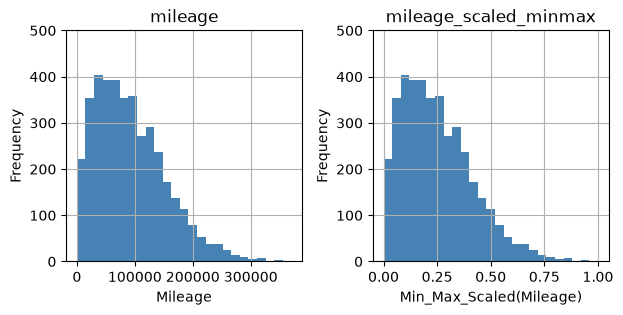

In [361]:
# Min-Max scaling of the variable 'mileage' (by hand)
df['mileage_scaled_minmax'] = ((df['mileage'] - df['mileage'].min())
                               / (df['mileage'].max() - df['mileage'].min()))

# Histogram of the variable 'mileage' and 'mileage_scaled_minmax'
ax = df[['mileage', 'mileage_scaled_minmax']].hist(bins=25,
                                                   figsize=(7, 3),
                                                   color='steelblue')

# Set the y-axis range for each subplot and add labels
for axis, label in zip(ax.flatten(), ['Mileage', 'Min_Max_Scaled(Mileage)']):
    axis.set_ylim(0, 500)
    axis.set_xlabel(label)
    axis.set_ylabel('Frequency')

# Display the plot
plt.show()

#### scikit-learn version

In [362]:
# Min-Max scaling of the variable 'mileage' (scikit-learn version)
from sklearn.preprocessing import MinMaxScaler

# Fit the scaler and transform the variable
# (note the double brackets: scikit-learn expects a 2D input)
scaler = MinMaxScaler()
df['mileage_scaled_minmax_sklearn'] = scaler.fit_transform(
    df[['mileage']]).ravel()

# Check that the by-hand and scikit-learn versions give the same result
print(np.allclose(df['mileage_scaled_minmax'],
                  df['mileage_scaled_minmax_sklearn']))

True


### Max-Absolute Scaling

#### By hand

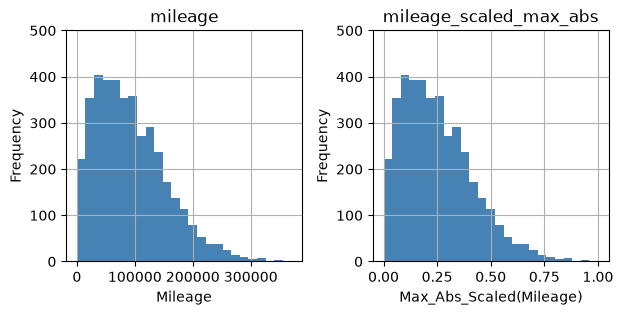

In [363]:
# Max-Absolute scaling of the variable 'mileage' (by hand)
df['mileage_scaled_max_abs'] = df['mileage'] / df['mileage'].abs().max()

# Histogram of the variable 'mileage' and 'mileage_scaled_max_abs'
ax = df[['mileage', 'mileage_scaled_max_abs']].hist(bins=25,
                                                    figsize=(7, 3),
                                                    color='steelblue')

# Set the y-axis range for each subplot and add labels
for axis, label in zip(ax.flatten(), ['Mileage', 'Max_Abs_Scaled(Mileage)']):
    axis.set_ylim(0, 500)
    axis.set_xlabel(label)
    axis.set_ylabel('Frequency')

# Display the plot
plt.show()

#### scikit-learn version

In [364]:
# Max-Absolute scaling of the variable 'mileage' (scikit-learn version)
from sklearn.preprocessing import MaxAbsScaler

# Fit the scaler and transform the variable
# (note the double brackets: scikit-learn expects a 2D input)
scaler = MaxAbsScaler()
df['mileage_scaled_max_abs_sklearn'] = scaler.fit_transform(
    df[['mileage']]).ravel()

# Check that the by-hand and scikit-learn versions give the same result
print(np.allclose(df['mileage_scaled_max_abs'],
                  df['mileage_scaled_max_abs_sklearn']))

True


### Robust Scaling

#### By hand

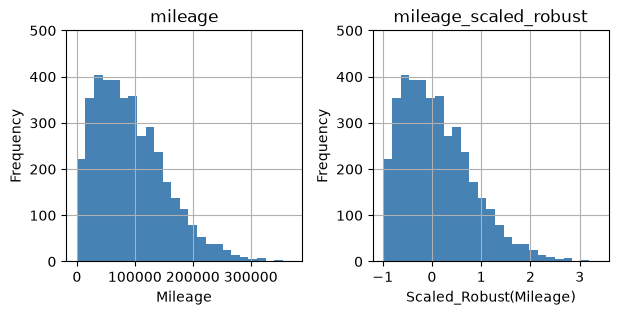

In [365]:
# Robust scaling of the variable 'mileage' (by hand)
df['mileage_scaled_robust'] = (df['mileage'] - df['mileage'].median()) / \
    (df['mileage'].quantile(0.75)
     - df['mileage'].quantile(0.25))

# Histogram of the variable 'mileage' and 'mileage_scaled_robust'
ax = df[['mileage', 'mileage_scaled_robust']].hist(bins=25,
                                                   figsize=(7, 3),
                                                   color='steelblue')

# Set the y-axis range for each subplot and add labels
for axis, label in zip(ax.flatten(), ['Mileage', 'Scaled_Robust(Mileage)']):
    axis.set_ylim(0, 500)
    axis.set_xlabel(label)
    axis.set_ylabel('Frequency')

# Display the plot
plt.show()

#### scikit-learn version

In [366]:
# Robust scaling of the variable 'mileage' (scikit-learn version)
from sklearn.preprocessing import RobustScaler

# Fit the scaler and transform the variable
# (note the double brackets: scikit-learn expects a 2D input)
scaler = RobustScaler()
df['mileage_scaled_robust_sklearn'] = scaler.fit_transform(
    df[['mileage']]).ravel()

# Check that the by-hand and scikit-learn versions give the same result
print(np.allclose(df['mileage_scaled_robust'],
                  df['mileage_scaled_robust_sklearn']))

True


## Standardization

### Z-score Normalization

#### By hand

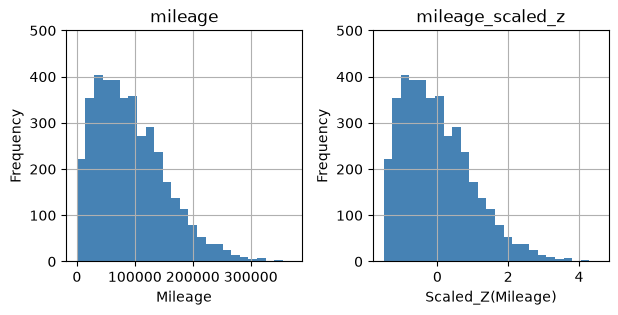

In [367]:
# Z-score Normalization of the variable 'mileage' (by hand)
df['mileage_scaled_z'] = ((df['mileage'] - df['mileage'].mean())
                          / df['mileage'].std())

# Histogram of the variable 'mileage' and 'mileage_scaled_z'
ax = df[['mileage', 'mileage_scaled_z']].hist(bins=25,
                                              figsize=(7, 3),
                                              color='steelblue')

# Set the y-axis range for each subplot and add labels
for axis, label in zip(ax.flatten(), ['Mileage', 'Scaled_Z(Mileage)']):
    axis.set_ylim(0, 500)
    axis.set_xlabel(label)
    axis.set_ylabel('Frequency')

# Display the plot
plt.show()

#### scikit-learn version

In [368]:
# Z-score Normalization of the variable 'mileage' (scikit-learn version)
from sklearn.preprocessing import StandardScaler

# Fit the scaler and transform the variable
# (note the double brackets: scikit-learn expects a 2D input)
scaler = StandardScaler()
df['mileage_scaled_z_sklearn'] = scaler.fit_transform(
    df[['mileage']]).ravel()

# Note: pandas .std() divides by n-1, StandardScaler divides by n,
# so the results differ slightly
print(np.allclose(df['mileage_scaled_z'],
                  df['mileage_scaled_z_sklearn']))

# Check against the by-hand formula with the standard deviation
# divided by n (ddof=0)
z_ddof0 = (df['mileage'] - df['mileage'].mean()) / df['mileage'].std(ddof=0)
print(np.allclose(z_ddof0, df['mileage_scaled_z_sklearn']))

False
True


## Transformation

### Log-Transformation

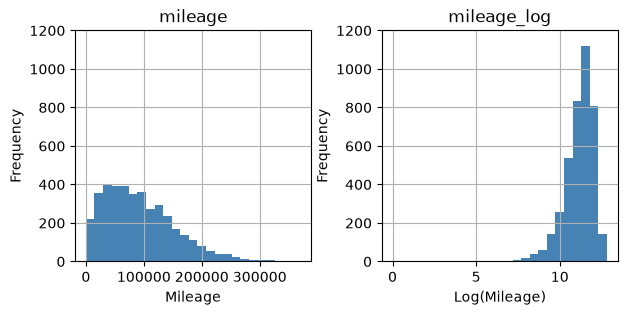

In [369]:
# Log-Transformation of the variable 'mileage'
df['mileage_log'] = np.log(df['mileage'])

# Histogram of the variable 'mileage' and 'mileage_log'
ax = df[['mileage', 'mileage_log']].hist(bins=25,
                                         figsize=(7, 3),
                                         color='steelblue')

# Set the y-axis range for each subplot and add labels
for axis, label in zip(ax.flatten(), ['Mileage', 'Log(Mileage)']):
    axis.set_ylim(0, 1200)
    axis.set_xlabel(label)
    axis.set_ylabel('Frequency')

# Display the plot
plt.show()

### SQRT-Transformation

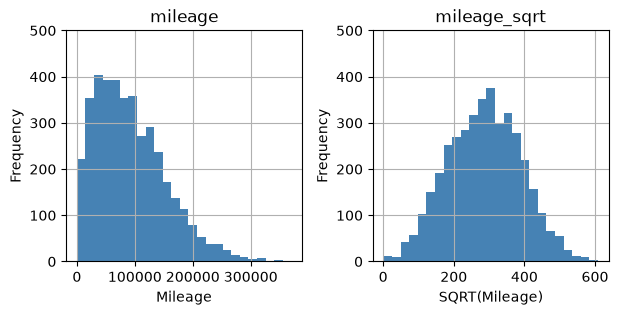

In [370]:
# SQRT-Transformation of the variable 'mileage'
df['mileage_sqrt'] = np.sqrt(df['mileage'])

# Histogram of the variable 'mileage' and 'mileage_sqrt'
ax = df[['mileage', 'mileage_sqrt']].hist(bins=25,
                                          figsize=(7, 3),
                                          color='steelblue')

# Set the y-axis range for each subplot and add labels
for axis, label in zip(ax.flatten(), ['Mileage', 'SQRT(Mileage)']):
    axis.set_ylim(0, 500)
    axis.set_xlabel(label)
    axis.set_ylabel('Frequency')

# Display the plot
plt.show()

### Box-Cox Transformation

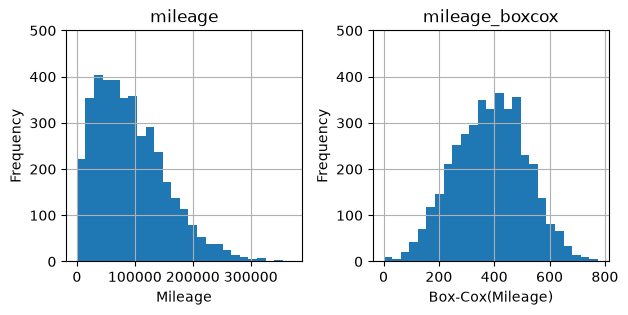

In [371]:
# Import the boxcox function from scipy
from scipy.stats import boxcox

# Box-Cox Transformation of the variable 'mileage'
df['mileage_boxcox'], _ = boxcox(df['mileage'])

# Histogram of the variable 'mileage' and 'mileage_boxcox'
ax = df[['mileage', 'mileage_boxcox']].hist(bins=25,
                                            figsize=(7, 3))

# Set the y-axis range for each subplot and add labels
for axis, label in zip(ax.flatten(), ['Mileage', 'Box-Cox(Mileage)']):
    axis.set_ylim(0, 500)
    axis.set_xlabel(label)
    axis.set_ylabel('Frequency')

# Display the plot
plt.show()

## Combining & organizing data

### Reading car data with geocoded addresses

In [372]:
# Meaning of variables
# offer_id: unique identifier of the offer on autoscout24.ch
# lat: geographical latitude
# lon: geographical longitude
# bfs_number: official municipality id
# bfs_name: official municipality name

# Geocoded data (i.e. data with latitude and longitude)
df_geo = pd.read_csv('./Data/autoscout24_data_geocoded.csv', sep=';')

print(df_geo.dtypes)

# Show data
df_geo.head()

offer_id        int64
lat           float64
lon           float64
bfs_number      int64
bfs_name          str
dtype: object


,offer_id,lat,lon,bfs_number,bfs_name
0,7324420,47.434376,8.859333,228,Turbenthal
1,7512768,46.850327,7.200491,2293,Düdingen
2,7512034,46.386593,6.204862,5716,Eysins
3,7512728,47.542408,7.873130,4263,Zeiningen
4,7490242,47.067474,7.302120,306,Lyss


### Join geo-information to car data using .merge()

In [373]:
# Merge geo-information to the car data (the key is 'offer_id')
df = df.merge(df_geo[['offer_id',
                       'lat',
                       'lon',
                       'bfs_name', 
                       'bfs_number']],
               on="offer_id")

# Show data
df.head()

,url_short,offer_id,scrape_dt,type,price_raw,hp_raw,init_regist,mileage_raw,fuel_type,transmission,...,mileage_scaled_robust_sklearn,mileage_scaled_z,mileage_scaled_z_sklearn,mileage_log,mileage_sqrt,mileage_boxcox,lat,lon,bfs_name,bfs_number
0,https://www.autoscout24.ch/7324420,7324420,2020_03_17 07:34:45,AUDI A5 SPORTBACK 3.0 TDI QUATTRO S-TRONIC (LI...,CHF 22'500.–,245 PS,10.2014,75'000 km,Diesel,Automatisiertes Schaltgetriebe,...,-0.100000,-0.293830,-0.293867,11.225243,273.861279,371.799266,47.434376,8.859333,Turbenthal,228
1,https://www.autoscout24.ch/7512768,7512768,2020_03_17 07:34:55,MERCEDES-BENZ SLK 200 7G-TRONIC (CABRIOLET),CHF 23'749.–,184 PS,6.2013,46'655 km,Benzin,Automat sequentiell,...,-0.433471,-0.757757,-0.757852,10.750535,215.997685,298.687292,46.850327,7.200491,Düdingen,2293
2,https://www.autoscout24.ch/7512034,7512034,2020_03_17 07:35:03,MERCEDES-BENZ C 350 AVANTGARDE 4MATIC 7G-TRONI...,CHF 18'500.–,306 PS,6.2011,138'955 km,Benzin,Automat sequentiell,...,0.652412,0.752931,0.753026,11.841905,372.766683,493.921372,46.386593,6.204862,Eysins,5716
3,https://www.autoscout24.ch/7512728,7512728,2020_03_17 07:35:06,MERCEDES-BENZ A 45 AMG 4MATIC SPEEDSHIFT 7G-DC...,CHF 36'000.–,360 PS,8.2015,43'000 km,Benzin,Automatisiertes Schaltgetriebe,...,-0.476471,-0.817579,-0.817682,10.668955,207.364414,287.647489,47.542408,7.873130,Zeiningen,4263
4,https://www.autoscout24.ch/7490242,7490242,2020_03_17 07:35:16,AUDI A5 SPORTBACK 2.0 TFSI SPORT QUATTRO S-TRO...,CHF 48'500.–,252 PS,9.2018,43'300 km,Benzin,Automatisiertes Schaltgetriebe,...,-0.472941,-0.812669,-0.812771,10.675908,208.086520,288.572334,47.067474,7.302120,Lyss,306


### Reading municipality-level data from an .xlsx - file

In [374]:
# Meaning of variables:
# bfs_number: municipality id
# bfs_name: municipality name
# pop: number of residents
# pop_dens: population density per km2
# frg_pct: percentage foreigners
# emp: number of employees

# Read municipality-level data from the .xlsx file
df_m = pd.read_excel('./Data/municipality_data.xlsx', sheet_name="data_for_import")

# Show data
df_m.head()

,bfs_number,bfs_name,pop,pop_dens,frg_pct,emp
0,1,Aeugst am Albis,1981,250.442478,14.184755,442.0
1,2,Affoltern am Albis,12303,1161.756374,28.700317,6920.0
2,3,Bonstetten,5572,749.932705,16.564968,1014.0
3,4,Hausen am Albis,3751,275.808824,16.022394,1021.0
4,5,Hedingen,3778,578.560490,16.410799,1478.0


### Join municipality-level data to the car data data using .merge()

In [375]:
df.head()

,url_short,offer_id,scrape_dt,type,price_raw,hp_raw,init_regist,mileage_raw,fuel_type,transmission,...,mileage_scaled_robust_sklearn,mileage_scaled_z,mileage_scaled_z_sklearn,mileage_log,mileage_sqrt,mileage_boxcox,lat,lon,bfs_name,bfs_number
0,https://www.autoscout24.ch/7324420,7324420,2020_03_17 07:34:45,AUDI A5 SPORTBACK 3.0 TDI QUATTRO S-TRONIC (LI...,CHF 22'500.–,245 PS,10.2014,75'000 km,Diesel,Automatisiertes Schaltgetriebe,...,-0.100000,-0.293830,-0.293867,11.225243,273.861279,371.799266,47.434376,8.859333,Turbenthal,228
1,https://www.autoscout24.ch/7512768,7512768,2020_03_17 07:34:55,MERCEDES-BENZ SLK 200 7G-TRONIC (CABRIOLET),CHF 23'749.–,184 PS,6.2013,46'655 km,Benzin,Automat sequentiell,...,-0.433471,-0.757757,-0.757852,10.750535,215.997685,298.687292,46.850327,7.200491,Düdingen,2293
2,https://www.autoscout24.ch/7512034,7512034,2020_03_17 07:35:03,MERCEDES-BENZ C 350 AVANTGARDE 4MATIC 7G-TRONI...,CHF 18'500.–,306 PS,6.2011,138'955 km,Benzin,Automat sequentiell,...,0.652412,0.752931,0.753026,11.841905,372.766683,493.921372,46.386593,6.204862,Eysins,5716
3,https://www.autoscout24.ch/7512728,7512728,2020_03_17 07:35:06,MERCEDES-BENZ A 45 AMG 4MATIC SPEEDSHIFT 7G-DC...,CHF 36'000.–,360 PS,8.2015,43'000 km,Benzin,Automatisiertes Schaltgetriebe,...,-0.476471,-0.817579,-0.817682,10.668955,207.364414,287.647489,47.542408,7.873130,Zeiningen,4263
4,https://www.autoscout24.ch/7490242,7490242,2020_03_17 07:35:16,AUDI A5 SPORTBACK 2.0 TFSI SPORT QUATTRO S-TRO...,CHF 48'500.–,252 PS,9.2018,43'300 km,Benzin,Automatisiertes Schaltgetriebe,...,-0.472941,-0.812669,-0.812771,10.675908,208.086520,288.572334,47.067474,7.302120,Lyss,306


In [376]:
# Merge needs a key which must be identical in both data sets
# (here the key is 'bfs_number')
df = df.merge(df_m[['bfs_number','frg_pct','pop_dens','pop', 'emp']],on="bfs_number")

# Show data
df.head()

,url_short,offer_id,scrape_dt,type,price_raw,hp_raw,init_regist,mileage_raw,fuel_type,transmission,...,mileage_sqrt,mileage_boxcox,lat,lon,bfs_name,bfs_number,frg_pct,pop_dens,pop,emp
0,https://www.autoscout24.ch/7324420,7324420,2020_03_17 07:34:45,AUDI A5 SPORTBACK 3.0 TDI QUATTRO S-TRONIC (LI...,CHF 22'500.–,245 PS,10.2014,75'000 km,Diesel,Automatisiertes Schaltgetriebe,...,273.861279,371.799266,47.434376,8.859333,Turbenthal,228,20.540651,193.616178,4883,1631.0
1,https://www.autoscout24.ch/7512768,7512768,2020_03_17 07:34:55,MERCEDES-BENZ SLK 200 7G-TRONIC (CABRIOLET),CHF 23'749.–,184 PS,6.2013,46'655 km,Benzin,Automat sequentiell,...,215.997685,298.687292,46.850327,7.200491,Düdingen,2293,14.228089,265.962289,8181,3982.0
2,https://www.autoscout24.ch/7512034,7512034,2020_03_17 07:35:03,MERCEDES-BENZ C 350 AVANTGARDE 4MATIC 7G-TRONI...,CHF 18'500.–,306 PS,6.2011,138'955 km,Benzin,Automat sequentiell,...,372.766683,493.921372,46.386593,6.204862,Eysins,5716,32.737752,728.991597,1735,1622.0
3,https://www.autoscout24.ch/7512728,7512728,2020_03_17 07:35:06,MERCEDES-BENZ A 45 AMG 4MATIC SPEEDSHIFT 7G-DC...,CHF 36'000.–,360 PS,8.2015,43'000 km,Benzin,Automatisiertes Schaltgetriebe,...,207.364414,287.647489,47.542408,7.873130,Zeiningen,4263,16.757665,209.410730,2381,571.0
4,https://www.autoscout24.ch/7490242,7490242,2020_03_17 07:35:16,AUDI A5 SPORTBACK 2.0 TFSI SPORT QUATTRO S-TRO...,CHF 48'500.–,252 PS,9.2018,43'300 km,Benzin,Automatisiertes Schaltgetriebe,...,208.086520,288.572334,47.067474,7.302120,Lyss,306,18.962963,1046.864464,15525,8495.0


### Sorting data

In [383]:
# Sorting data by 'price' and 'mileage' with highest price above
# (ascending=False)
df.sort_values(by=['price', 'mileage'], ascending=False)

# Show data
df[['type','price', 'mileage']].head()

,type,price,mileage
0,AUDI A5 SPORTBACK 3.0 TDI QUATTRO S-TRONIC (LI...,22500,75000
1,MERCEDES-BENZ SLK 200 7G-TRONIC (CABRIOLET),23749,46655
2,MERCEDES-BENZ C 350 AVANTGARDE 4MATIC 7G-TRONI...,18500,138955
3,MERCEDES-BENZ A 45 AMG 4MATIC SPEEDSHIFT 7G-DC...,36000,43000
4,AUDI A5 SPORTBACK 2.0 TFSI SPORT QUATTRO S-TRO...,48500,43300


### Reshaping data

#### Reshaping data using .stack() and .unstack()

In [378]:
# Create a subset of the data (first 5 rows)


# Reshape the data using .stack()


# Reshape the data back using .unstack()


#### Reshaping data using .melt()

In [379]:
# Create a subset of the data (first 5 rows)


# Reshape the data using .melt()


### Pivoting data using .pivot_table()

In [380]:
# Create a pivot table with the mean values per fuel type


# Format the values to 2 decimal places with trailing zeros


# Display the pivot table


### Jupyter notebook --footer info-- (please always provide this at the end of each notebook)

In [381]:
import os
import platform
import socket
from platform import python_version
from datetime import datetime

print('-----------------------------------')
print(os.name.upper())
print(platform.system(), '|', platform.release())
print('Datetime:', datetime.now().strftime("%Y-%m-%d %H:%M:%S"))
print('Python Version:', python_version())
print('-----------------------------------')

-----------------------------------
POSIX
Linux | 7.0.12-linuxkit
Datetime: 2026-10-18 09:52:07
Python Version: 3.11.17
-----------------------------------
